In [1]:
# All of the imports we require for the project 
import glob 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import chi2_contingency

In [2]:
# read the data from the species CSV file into pandas dataframe

species_info_df = pd.read_csv('species_info.csv')


# print the head of each the species dataframe
species_info_df.head()


,category,scientific_name,common_names,conservation_status
0,Mammal,Clethrionomys gapperi gapperi,Gapper's Red-Backed Vole,NaN
1,Mammal,Bos bison,"American Bison, Bison",NaN
2,Mammal,Bos taurus,"Aurochs, Aurochs, Domestic Cattle (Feral), Dom...",NaN
3,Mammal,Ovis aries,"Domestic Sheep, Mouflon, Red Sheep, Sheep (Feral)",NaN
4,Mammal,Cervus elaphus,Wapiti Or Elk,NaN


In [3]:
 # read the data from the observations CSV file into pandas dataframe

observations_df = pd.read_csv('observations.csv')
observations_df.head()

,scientific_name,park_name,observations
0,Vicia benghalensis,Great Smoky Mountains National Park,68
1,Neovison vison,Great Smoky Mountains National Park,77
2,Prunus subcordata,Yosemite National Park,138
3,Abutilon theophrasti,Bryce National Park,84
4,Githopsis specularioides,Great Smoky Mountains National Park,85


In [4]:
# use the info() method to get a concise summary of both dataframes 

species_info_df.info()
observations_df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5824 entries, 0 to 5823
Data columns (total 4 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   category             5824 non-null   object
 1   scientific_name      5824 non-null   object
 2   common_names         5824 non-null   object
 3   conservation_status  191 non-null    object
dtypes: object(4)
memory usage: 182.1+ KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23296 entries, 0 to 23295
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   scientific_name  23296 non-null  object
 1   park_name        23296 non-null  object
 2   observations     23296 non-null  int64 
dtypes: int64(1), object(2)
memory usage: 546.1+ KB


In [5]:
# use describe() method to get a statistical summary of both dataframes

species_info_df.describe()
print("\n")
print(observations_df.describe())



       observations
count  23296.000000
mean     142.287904
std       69.890532
min        9.000000
25%       86.000000
50%      124.000000
75%      195.000000
max      321.000000


In [6]:
# display column names for both dataframes
print(species_info_df.columns)
print(observations_df.columns)

Index(['category', 'scientific_name', 'common_names', 'conservation_status'], dtype='object')
Index(['scientific_name', 'park_name', 'observations'], dtype='object')


In [7]:
# get the sum of null values in each dataframe
print(species_info_df.isnull().sum())
print(observations_df.isnull().sum())


category                  0
scientific_name           0
common_names              0
conservation_status    5633
dtype: int64
scientific_name    0
park_name          0
observations       0
dtype: int64


In [8]:
# get the number of duplicate rows in each dataframe
print(species_info_df.duplicated().sum())
print("The number of duplicate rows in observations was initially 15")

# show the duplicate rows in the observations dataframe
observations_df[observations_df.duplicated()]

# drop the duplicate rows in the observations dataframe
observations_df = observations_df.drop_duplicates()

# get the number of duplicate rows in observations dataframe after dropping duplicates

print(observations_df.duplicated().sum())

0
The number of duplicate rows in observations was initially 15
0


In [9]:
# investigate categorical columns in the species_info_df dataframe
print(species_info_df['category'].value_counts())

print(species_info_df['conservation_status'].value_counts())

# print the unique values in the category and conservation_status columns of the species_info_df dataframe
print(species_info_df['category'].unique())

print(species_info_df['conservation_status'].unique())


category
Vascular Plant       4470
Bird                  521
Nonvascular Plant     333
Mammal                214
Fish                  127
Amphibian              80
Reptile                79
Name: count, dtype: int64
conservation_status
Species of Concern    161
Endangered             16
Threatened             10
In Recovery             4
Name: count, dtype: int64
['Mammal' 'Bird' 'Reptile' 'Amphibian' 'Fish' 'Vascular Plant'
 'Nonvascular Plant']
[nan 'Species of Concern' 'Endangered' 'Threatened' 'In Recovery']


In [10]:
# investigate categorical columns in the observations_df dataframe
print(observations_df["park_name"].unique())

['Great Smoky Mountains National Park' 'Yosemite National Park'
 'Bryce National Park' 'Yellowstone National Park']


In [11]:
# hone in on the missing values in the conservation_status column of the species_info_df dataframe
print(species_info_df["conservation_status"].value_counts(dropna=False))

# display the rows where conservation_status is missing
print(species_info_df[species_info_df["conservation_status"].isnull()].head())

# couting the number of species in each category that are missing a conservation status
print(species_info_df[species_info_df["conservation_status"].isnull()]["category"].value_counts())

conservation_status
NaN                   5633
Species of Concern     161
Endangered              16
Threatened              10
In Recovery              4
Name: count, dtype: int64
  category                scientific_name  \
0   Mammal  Clethrionomys gapperi gapperi   
1   Mammal                      Bos bison   
2   Mammal                     Bos taurus   
3   Mammal                     Ovis aries   
4   Mammal                 Cervus elaphus   

                                        common_names conservation_status  
0                           Gapper's Red-Backed Vole                 NaN  
1                              American Bison, Bison                 NaN  
2  Aurochs, Aurochs, Domestic Cattle (Feral), Dom...                 NaN  
3  Domestic Sheep, Mouflon, Red Sheep, Sheep (Feral)                 NaN  
4                                      Wapiti Or Elk                 NaN  
category
Vascular Plant       4424
Bird                  442
Nonvascular Plant     328
Mammal     

In [12]:
# fill the missing values in the conservation_status column with "No concern"
species_info_df['conservation_status'] = species_info_df['conservation_status'].fillna('No concern')

# print the value counts of the conservation_status column after filling missing values
print(species_info_df["conservation_status"].value_counts(dropna=False))

conservation_status
No concern            5633
Species of Concern     161
Endangered              16
Threatened              10
In Recovery              4
Name: count, dtype: int64


In [14]:
# show conservation status counts as a percentage 
conservation_status_counts = species_info_df['conservation_status'].value_counts()
conservation_status_percentages = (conservation_status_counts / len(species_info_df)) * 100
print(conservation_status_percentages)

conservation_status
No concern            96.720467
Species of Concern     2.764423
Endangered             0.274725
Threatened             0.171703
In Recovery            0.068681
Name: count, dtype: float64


In [16]:
# we now want to analyse the distribution of conservation status across different animals
# produce a cross-tabulation of the category and conservation_status columns
cat_conservation_ct = pd.crosstab(species_info_df['category'], species_info_df['conservation_status'])
cat_conservation_ct



conservation_status,Endangered,In Recovery,No concern,Species of Concern,Threatened
category,,,,,
Amphibian,1,0,73,4,2
Bird,4,3,442,72,0
Fish,3,0,116,4,4
Mammal,7,1,176,28,2
Nonvascular Plant,0,0,328,5,0
Reptile,0,0,74,5,0
Vascular Plant,1,0,4424,43,2


In [17]:
# produce a proportion contingency table by dividing each cell in the cross-tabulation by the total number of observations
cat_conservation_prop = np.round(cat_conservation_ct / len(species_info_df) * 100,2)
cat_conservation_prop

conservation_status,Endangered,In Recovery,No concern,Species of Concern,Threatened
category,,,,,
Amphibian,0.02,0.00,1.25,0.07,0.03
Bird,0.07,0.05,7.59,1.24,0.00
Fish,0.05,0.00,1.99,0.07,0.07
Mammal,0.12,0.02,3.02,0.48,0.03
Nonvascular Plant,0.00,0.00,5.63,0.09,0.00
Reptile,0.00,0.00,1.27,0.09,0.00
Vascular Plant,0.02,0.00,75.96,0.74,0.03


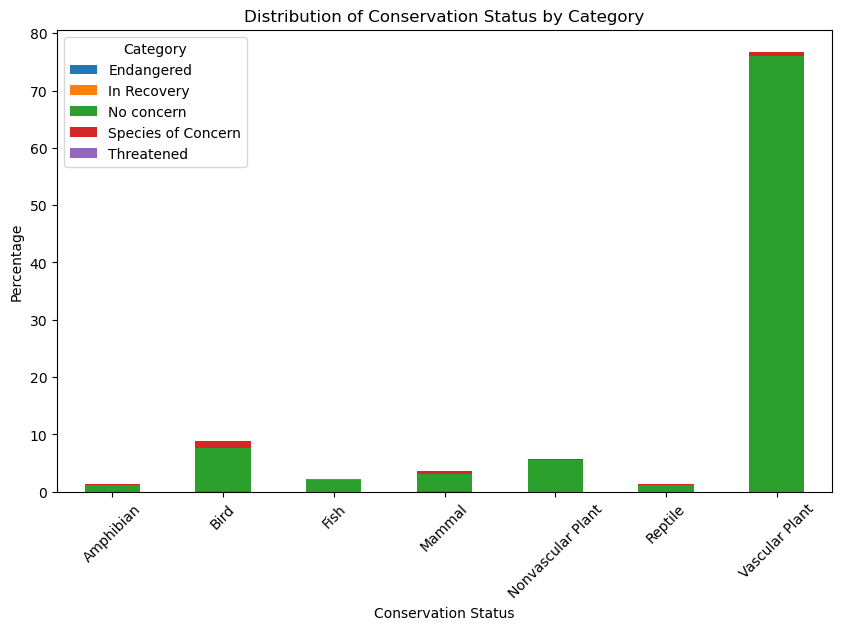

In [20]:
# visualise the proportion contingency table as a stacked bar chart
cat_conservation_prop.plot(kind='bar', stacked=True, figsize=(10,6))
plt.xlabel('Conservation Status')
plt.ylabel('Percentage')
plt.title('Distribution of Conservation Status by Category')
plt.legend(title='Category', loc = 'upper left')
plt.xticks(rotation=45)
plt.show()


In [21]:
# add an is_protected column to the species_info_df dataframe that is True if the conservation_status is not "No concern" and False otherwise
species_info_df['is_protected'] = species_info_df['conservation_status'] != 'No concern'
species_info_df.head()

,category,scientific_name,common_names,conservation_status,is_protected
0,Mammal,Clethrionomys gapperi gapperi,Gapper's Red-Backed Vole,No concern,False
1,Mammal,Bos bison,"American Bison, Bison",No concern,False
2,Mammal,Bos taurus,"Aurochs, Aurochs, Domestic Cattle (Feral), Dom...",No concern,False
3,Mammal,Ovis aries,"Domestic Sheep, Mouflon, Red Sheep, Sheep (Feral)",No concern,False
4,Mammal,Cervus elaphus,Wapiti Or Elk,No concern,False


In [22]:
# get and display the count of protected and not protected species
protected_counts = species_info_df['is_protected'].value_counts()
print(protected_counts)

is_protected
False    5633
True      191
Name: count, dtype: int64


In [23]:
# create cross-tabulation of category and is_protected columns
category_protection_ct = pd.crosstab(species_info_df['category'], species_info_df['is_protected'])
category_protection_ct

is_protected,False,True
category,,
Amphibian,73,7
Bird,442,79
Fish,116,11
Mammal,176,38
Nonvascular Plant,328,5
Reptile,74,5
Vascular Plant,4424,46


In [ ]:
# now create a normalized cross-tabulation of category and is_protected columns to get the proportion of protected species in each category
category_protection_prop = pd.crosstab(species_info_df['category'], species_info_df['is_protected'], normalize='index') * 100
category_protection_prop


is_protected,False,True
category,,
Amphibian,91.250000,8.750000
Bird,84.836852,15.163148
Fish,91.338583,8.661417
Mammal,82.242991,17.757009
Nonvascular Plant,98.498498,1.501502
Reptile,93.670886,6.329114
Vascular Plant,98.970917,1.029083


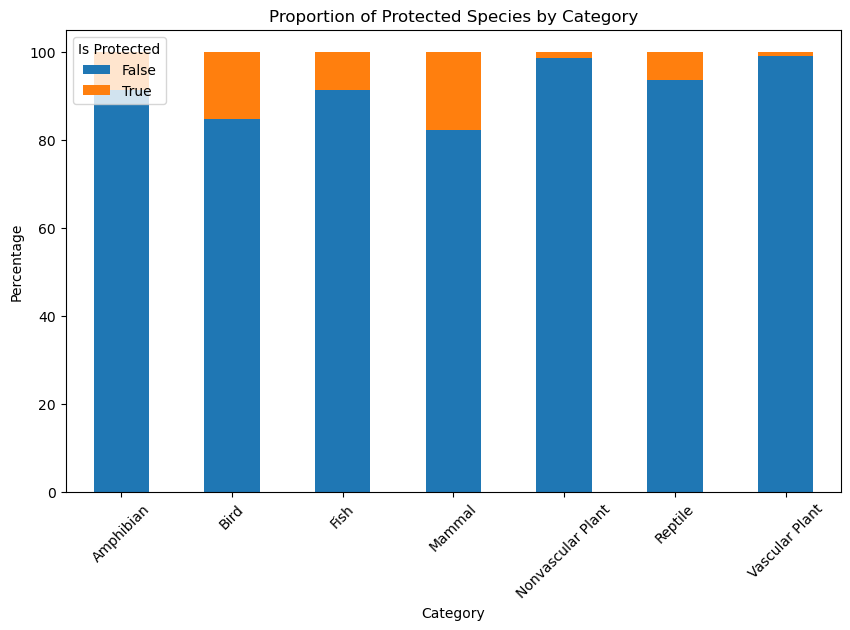

<Figure size 640x480 with 0 Axes>

In [ ]:
# plot the normalized contingency table as a stacked bar chart

ax = category_protection_prop.plot(kind='bar', stacked=True, figsize=(10,6))
plt.xlabel('Category')
plt.ylabel('Percentage')
plt.title('Proportion of Protected Species by Category')
plt.legend(title='Is Protected', loc = 'upper left')
plt.xticks(rotation=45)
plt.show()

plt.savefig('proportion_protected_species_by_category.png')

The total number of observations in the data frame is: 3312429
The mean number of observations in the data frame is: 142.28035737296509


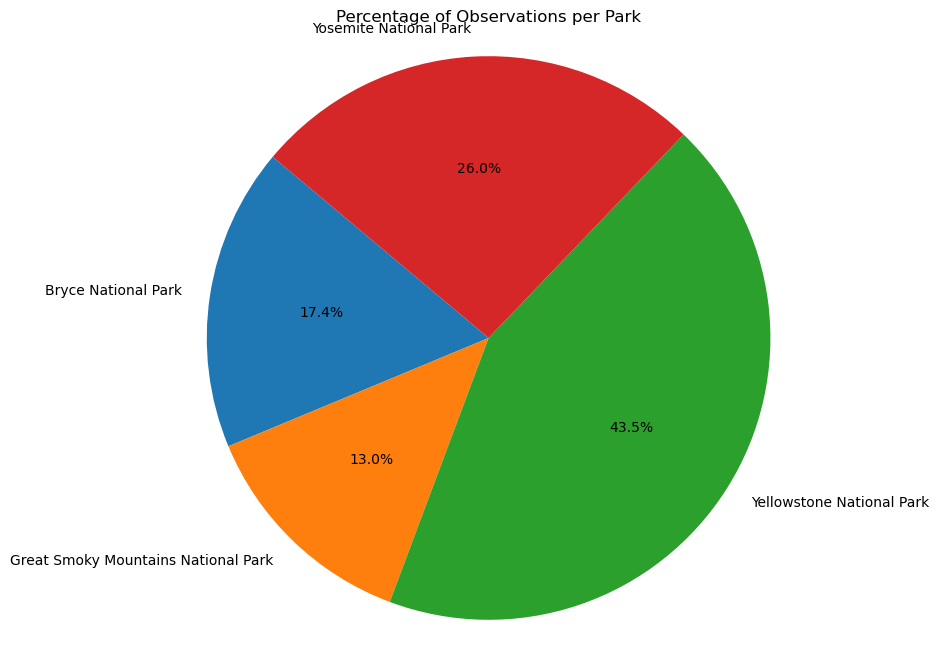

<Figure size 640x480 with 0 Axes>

In [43]:
# get the sum of observations in the data frame 
total_observations = observations_df['observations'].sum()
print(f'The total number of observations in the data frame is: {total_observations}')

# get the mean number of observations in the data frame
mean_observations = observations_df['observations'].mean()
print(f'The mean number of observations in the data frame is: {mean_observations}')

# get the total observations per park
observations_per_park = observations_df.groupby('park_name')['observations'].sum().reset_index()
observations_per_park

# get the percetnage of observations per park
observations_per_park['percentage'] = (observations_per_park['observations'] / total_observations) * 100
observations_per_park

# visualise the percentage of observations per park as a pie chart
plt.figure(figsize=(8,8))
plt.pie(observations_per_park['percentage'], labels=observations_per_park['park_name'], autopct='%1.1f%%', startangle=140)
plt.title('Percentage of Observations per Park')
plt.axis('equal')
plt.show()

plt.savefig('percentage_of_observations_per_park.png', bbox_inches='tight', dpi=300)

In [ ]:
# calculate the chi square statistic for the contingency table of category and is_protected columns
chi2, pval, dof, expected = chi2_contingency(category_protection_ct)
print(f'Chi-square statistic: {chi2}')
print(np.round(expected, 2))

# convert the expected counts to a dataframe for better readability
expected_df = pd.DataFrame(
    expected, 
    index=category_protection_ct.index, 
    columns=category_protection_ct.columns
)

print("Expected Counts Table:")
print(expected_df.round(2))

print("Actual Counts Table:")
print(category_protection_ct)

Chi-square statistic: 469.5114395774195
[[7.7380e+01 2.6200e+00]
 [5.0391e+02 1.7090e+01]
 [1.2283e+02 4.1700e+00]
 [2.0698e+02 7.0200e+00]
 [3.2208e+02 1.0920e+01]
 [7.6410e+01 2.5900e+00]
 [4.3234e+03 1.4660e+02]]
Expected Counts Table:
is_protected         False   True 
category                          
Amphibian            77.38    2.62
Bird                503.91   17.09
Fish                122.83    4.17
Mammal              206.98    7.02
Nonvascular Plant   322.08   10.92
Reptile              76.41    2.59
Vascular Plant     4323.40  146.60
Actuak Counts Table:
is_protected       False  True 
category                       
Amphibian             73      7
Bird                 442     79
Fish                 116     11
Mammal               176     38
Nonvascular Plant    328      5
Reptile               74      5
Vascular Plant      4424     46


In [57]:
# we now want to get the most observed category at each park

# start by merging the species_info_df and observations_df dataframes on the 'scientific_name' column
merged_df = pd.merge(species_info_df, observations_df, on='scientific_name', how='inner')

# group the merged dataframe by park_name and category, and sum the observations
grouped_df = merged_df.groupby(['park_name', 'category']).sum().reset_index()

# find the category with the maximum observations for each park
most_observed_category_per_park = grouped_df.loc[grouped_df.groupby('park_name')['observations'].idxmax()]
most_observed_category_per_park

,park_name,category,scientific_name,common_names,conservation_status,is_protected,observations
6,Bryce National Park,Vascular Plant,Acorus calamusAlisma subcordatumSagittaria aus...,SweetflagWater-PlantainLongbeak ArrowheadBroad...,No concernNo concernNo concernNo concernNo con...,46,484125
13,Great Smoky Mountains National Park,Vascular Plant,Acorus calamusAlisma subcordatumSagittaria aus...,SweetflagWater-PlantainLongbeak ArrowheadBroad...,No concernNo concernNo concernNo concernNo con...,46,363998
20,Yellowstone National Park,Vascular Plant,Acorus calamusAlisma subcordatumSagittaria aus...,SweetflagWater-PlantainLongbeak ArrowheadBroad...,No concernNo concernNo concernNo concernNo con...,46,1216688
27,Yosemite National Park,Vascular Plant,Acorus calamusAlisma subcordatumSagittaria aus...,SweetflagWater-PlantainLongbeak ArrowheadBroad...,No concernNo concernNo concernNo concernNo con...,46,726903


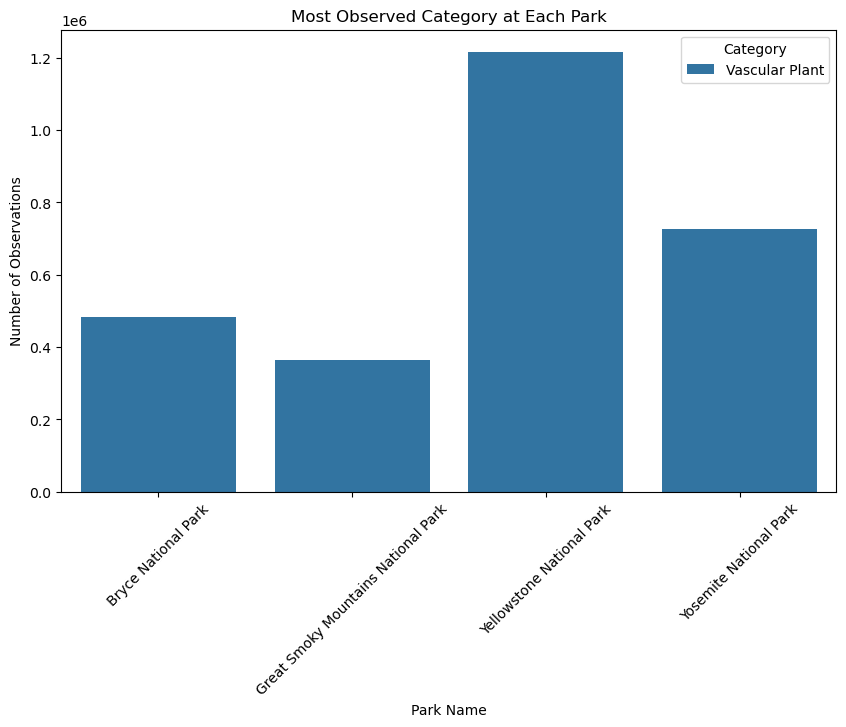

In [58]:
# visualise the most observed category at each park as a bar chart
plt.figure(figsize=(10,6))
sns.barplot(data=most_observed_category_per_park, x='park_name', y='observations', hue='category')
plt.title('Most Observed Category at Each Park')
plt.xlabel('Park Name')
plt.ylabel('Number of Observations')
plt.legend(title='Category', loc='upper right')
plt.xticks(rotation=45)
plt.show()